**Customer Sentiment Analysis on Flipkart Product Reviews**

**Data Analytics Capstone Project**

**Submitted By:** Yerramilli Lakshmi Sarvani

**Dataset:** Flipkart Product Reviews

**Tools Used:**
- Google Colab
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- TextBlob
- WordCloud

**Project Overview**

This project analyzes customer reviews from Flipkart to understand customer sentiment using Natural Language Processing (NLP). The study includes data cleaning, exploratory data analysis, sentiment classification, visualization, and business insights.

I) DATA UNDERSTANDING AND DATA CLEANING

Customer Sentiment Analysis on Flipkart Product Reviews

Step 1: Import Required Libraries

The first step is to import all the libraries required for data manipulation, visualization, and sentiment analysis.

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import re
import string

from textblob import TextBlob

from wordcloud import WordCloud

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline


Step 2: Load the Dataset

The Flipkart customer review dataset is loaded using the Pandas library and the Google Colab file upload method.

In [ ]:
from google.colab import files
uploaded=files.upload()
df = pd.read_csv("flipkart.csv")
df.head()

Saving flipkart.csv to flipkart.csv


,Unnamed: 0,Product_name,Review,Rating
0,0,Lenovo Ideapad Gaming 3 Ryzen 5 Hexa Core 5600...,Best under 60k Great performanceI got it for a...,5
1,1,Lenovo Ideapad Gaming 3 Ryzen 5 Hexa Core 5600...,Good perfomence...,5
2,2,Lenovo Ideapad Gaming 3 Ryzen 5 Hexa Core 5600...,Great performance but usually it has also that...,5
3,3,DELL Inspiron Athlon Dual Core 3050U - (4 GB/2...,My wife is so happy and best product 👌🏻😘,5
4,4,DELL Inspiron Athlon Dual Core 3050U - (4 GB/2...,"Light weight laptop with new amazing features,...",5


Step 3: Understanding the Dataset

Before performing any analysis, it is important to understand the structure of the dataset.

In [ ]:
print("Rows and Columns:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

Rows and Columns: (2304, 4)

Columns:
Index(['Unnamed: 0', 'Product_name', 'Review', 'Rating'], dtype='object')

Data Types:
Unnamed: 0       int64
Product_name    object
Review          object
Rating           int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2304 entries, 0 to 2303
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Unnamed: 0    2304 non-null   int64 
 1   Product_name  2304 non-null   object
 2   Review        2304 non-null   object
 3   Rating        2304 non-null   int64 
dtypes: int64(2), object(2)
memory usage: 72.1+ KB


Step 4: Display Sample Records

Displaying the first and last five records helps in understanding how the data is stored.

In [ ]:
df.head()
df.tail()

,Unnamed: 0,Product_name,Review,Rating
2299,2299,MSI 27 inch Full HD IPS Panel Monitor (PRO MP2...,"Great display, accurate colours at this price ...",5
2300,2300,MSI 27 inch Full HD IPS Panel Monitor (PRO MP2...,Superb monitor first brought 1 used for 2 mont...,5
2301,2301,MSI 27 inch Full HD IPS Panel Monitor (PRO MP2...,Awesome,5
2302,2302,MSI 27 inch Full HD IPS Panel Monitor (PRO MP2...,Only one issue with adapter,5
2303,2303,MSI 27 inch Full HD IPS Panel Monitor (PRO MP2...,Worth the money u spend for this monitor Great...,5


Step 5: Descriptive Statistics

The statistical summary provides information such as count, mean, minimum, maximum, and quartiles for numerical columns.

In [ ]:
df.describe()

,Unnamed: 0,Rating
count,2304.000000,2304.000000
mean,1151.500000,4.259549
std,665.251832,1.180017
min,0.000000,1.000000
25%,575.750000,4.000000
50%,1151.500000,5.000000
75%,1727.250000,5.000000
max,2303.000000,5.000000


Step 6: Missing Value Analysis

Missing values can affect the quality of analysis. Therefore, each column is checked for null values.

In [ ]:
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values)

Missing Values:
Unnamed: 0      0
Product_name    0
Review          0
Rating          0
dtype: int64


Observation

No missing values were found in the dataset. Therefore, no data imputation or removal was required.

Step 7: Handling Missing Values

Since the dataset contains no missing values, no cleaning operation was required.

In [ ]:
df = df.dropna()

print("Dataset Shape after handling missing values:")
print(df.shape)

Dataset Shape after handling missing values:
(2304, 4)


Step 8: Duplicate Record Analysis

Duplicate records can lead to biased analysis. Hence, duplicate rows are identified and removed if necessary.

In [ ]:
duplicates = df.duplicated().sum()

print("Duplicate Records:", duplicates)

Duplicate Records: 0


In [ ]:
df = df.drop_duplicates()

print("Dataset Shape after removing duplicates:")
print(df.shape)

Dataset Shape after removing duplicates:
(2304, 4)


Step 10: Removing Unnecessary Columns

The column 'Unnamed: 0' acts only as an index and does not contribute to the analysis. Therefore, it is removed.

In [ ]:
df.drop(columns=['Unnamed: 0'], inplace=True)
df.columns

Index(['Product_name', 'Review', 'Rating'], dtype='object')

II) EXPLORATORY DATA ANALYSIS (EDA)

RATING DISTRIBUTION

Distribution of Customer Ratings

This visualization shows how customers have rated the products on a scale of 1 to 5 stars.

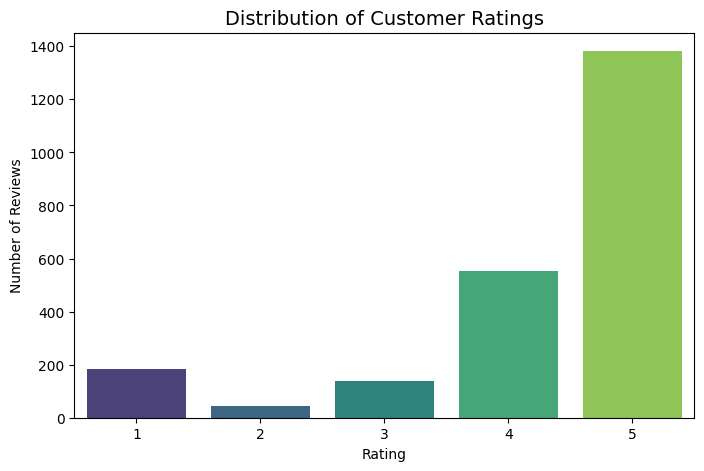

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Rating',
    data=df,
    palette='viridis'
)

plt.title("Distribution of Customer Ratings", fontsize=14)
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

plt.show()

PERCENTAGE DISTRIBUTION OF RATINGS

- The pie chart provides a percentage-wise representation of customer ratings.
- It helps understand the proportion of positive, neutral, and negative ratings in the dataset.

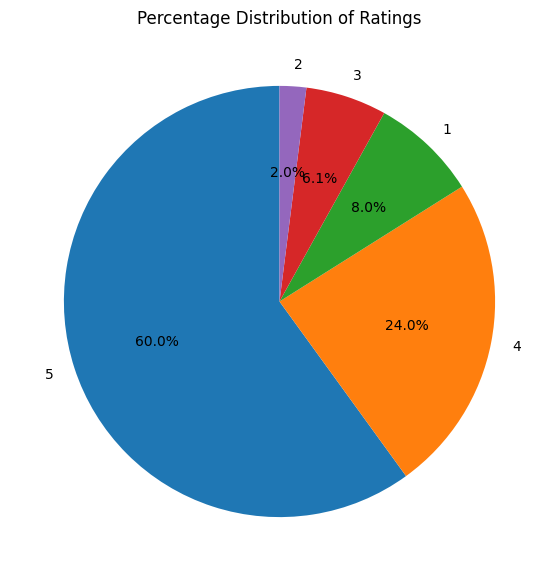

In [ ]:
rating_counts = df['Rating'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    rating_counts,
    labels=rating_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Percentage Distribution of Ratings")

plt.show()

REVIEW LENGTH ANALYSIS

- Most reviews are relatively short.
- A few reviews are much longer, indicating detailed customer feedback.
- Review length may influence sentiment analysis and customer engagement.

In [ ]:
df['Review_Length'] = df['Review'].apply(len)

df.head()

,Product_name,Review,Rating,Review_Length
0,Lenovo Ideapad Gaming 3 Ryzen 5 Hexa Core 5600...,Best under 60k Great performanceI got it for a...,5,324
1,Lenovo Ideapad Gaming 3 Ryzen 5 Hexa Core 5600...,Good perfomence...,5,18
2,Lenovo Ideapad Gaming 3 Ryzen 5 Hexa Core 5600...,Great performance but usually it has also that...,5,215
3,DELL Inspiron Athlon Dual Core 3050U - (4 GB/2...,My wife is so happy and best product 👌🏻😘,5,40
4,DELL Inspiron Athlon Dual Core 3050U - (4 GB/2...,"Light weight laptop with new amazing features,...",5,71


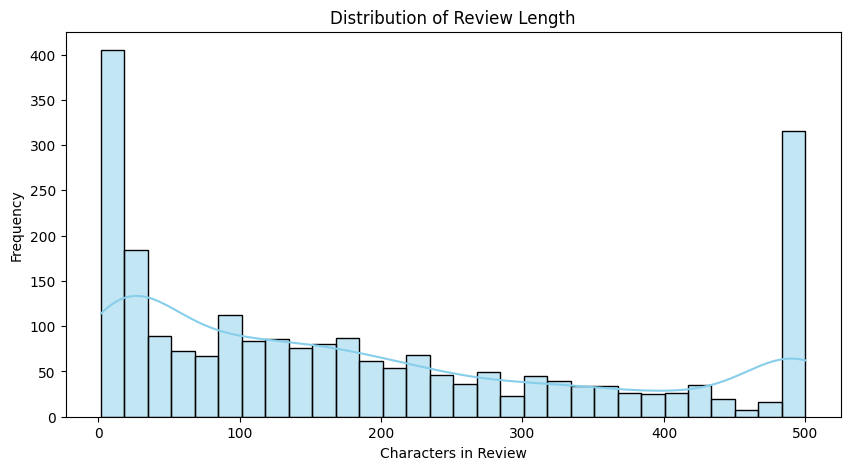

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    df['Review_Length'],
    bins=30,
    kde=True,
    color='skyblue'
)

plt.title("Distribution of Review Length")

plt.xlabel("Characters in Review")
plt.ylabel("Frequency")

plt.show()

REVIEW LENGTH VS RATING

- The boxplot compares review lengths across different ratings.
- Customers giving lower ratings may write longer reviews to explain their dissatisfaction.
- Higher ratings often correspond to shorter appreciation comments.

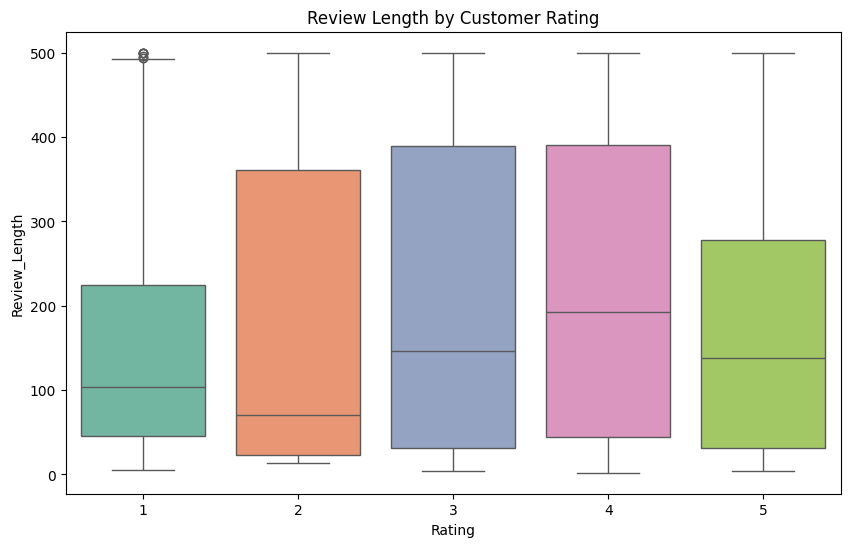

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x='Rating',
    y='Review_Length',
    data=df,
    palette='Set2'
)

plt.title("Review Length by Customer Rating")

plt.show()

TOP 10 MOST REVIEWED PRODUCTS

- The visualization identifies the products receiving the highest number of customer reviews.
- Products with more reviews generally have greater customer engagement.

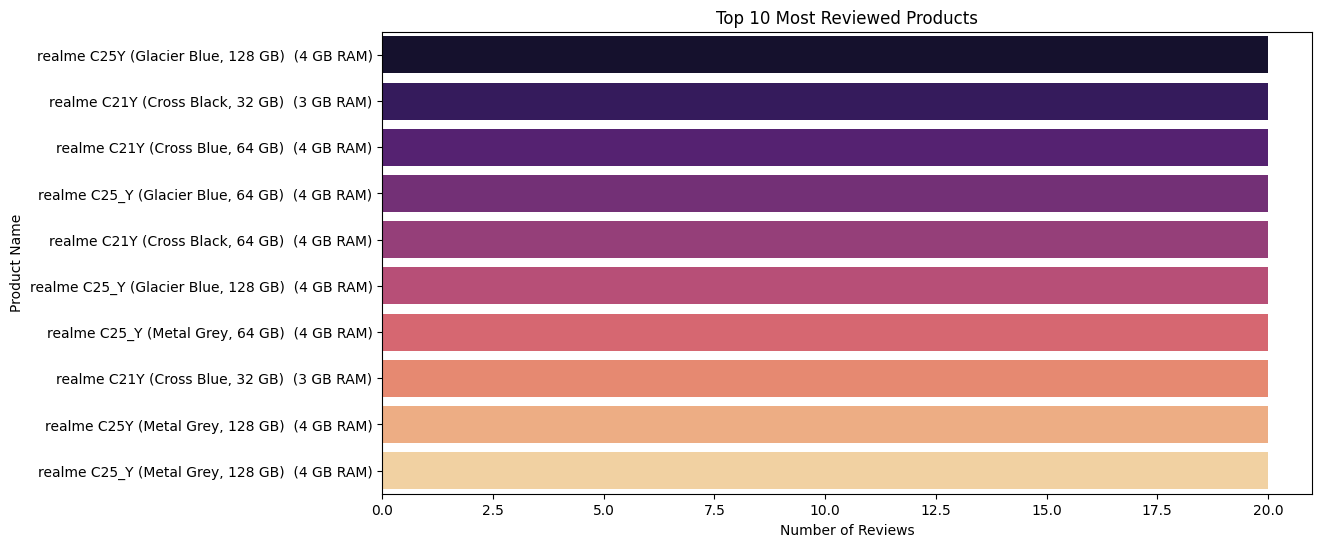

In [ ]:
top_products = df['Product_name'].value_counts().head(10)

plt.figure(figsize=(12,6))

sns.barplot(
    x=top_products.values,
    y=top_products.index,
    palette='magma'
)

plt.title("Top 10 Most Reviewed Products")

plt.xlabel("Number of Reviews")
plt.ylabel("Product Name")

plt.show()

AVERAGE RATING OF TOP PRODUCTS

- This chart highlights products with the highest average customer ratings.
- It helps identify products that consistently satisfy customers.

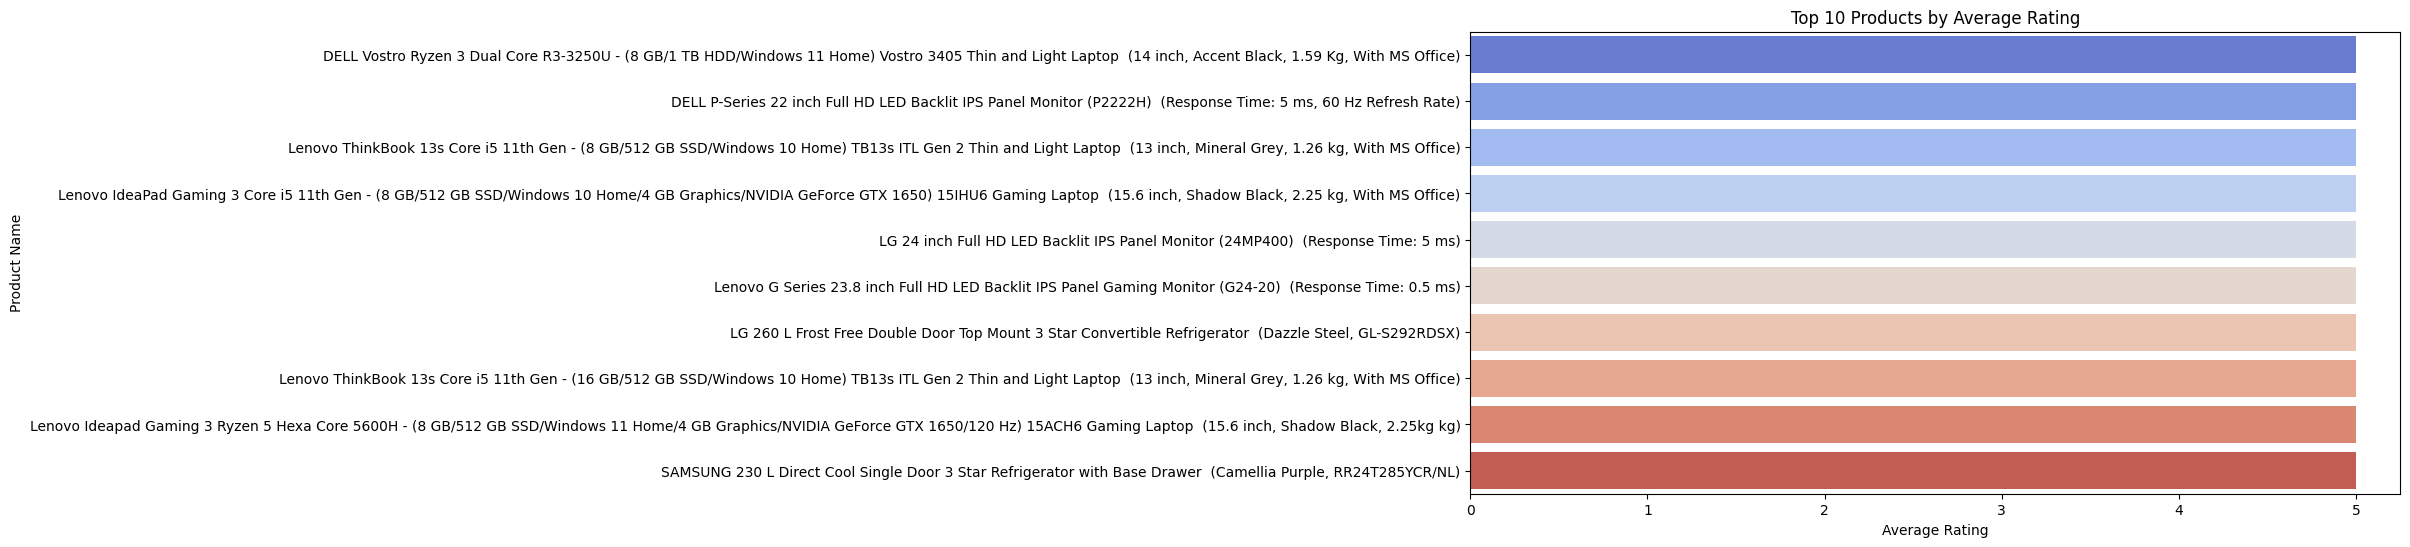

In [ ]:
# Create a copy for plotting
top_rating = (
    df.groupby('Product_name', as_index=False)['Rating']
      .mean()
      .sort_values(by='Rating', ascending=False)
      .head(10)
)

# Remove dollar signs from product names
top_rating['Product_name'] = top_rating['Product_name'].str.replace('$', '', regex=False)

plt.figure(figsize=(12,6))

sns.barplot(
    data=top_rating,
    x='Rating',
    y='Product_name',
    palette='coolwarm'
)

plt.title("Top 10 Products by Average Rating")
plt.xlabel("Average Rating")
plt.ylabel("Product Name")

plt.show()

CORRELATION HEATMAP

- The heatmap shows the relationship between review length and customer ratings.
- A correlation value close to zero indicates a weak relationship.

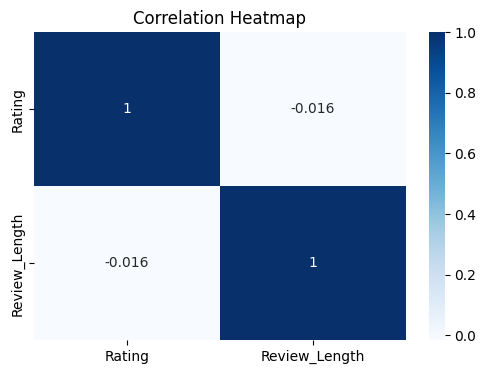

In [ ]:
plt.figure(figsize=(6,4))

sns.heatmap(
    df[['Rating','Review_Length']].corr(),
    annot=True,
    cmap='Blues'
)

plt.title("Correlation Heatmap")

plt.show()

III) TEXT PREPROCESSING AND SENTIMENT ANALYSIS

TEXT PREPROCESSING

Text Preprocessing

Customer reviews often contain punctuation, capital letters, extra spaces, and other unnecessary characters that can affect sentiment analysis.

Text preprocessing helps improve the quality of analysis by cleaning and standardizing the review text.

In [ ]:
# Convert reviews to lowercase
df['Clean_Review'] = df['Review'].str.lower()

df[['Review','Clean_Review']].head()

,Review,Clean_Review
0,Best under 60k Great performanceI got it for a...,best under 60k great performancei got it for a...
1,Good perfomence...,good perfomence...
2,Great performance but usually it has also that...,great performance but usually it has also that...
3,My wife is so happy and best product 👌🏻😘,my wife is so happy and best product 👌🏻😘
4,"Light weight laptop with new amazing features,...","light weight laptop with new amazing features,..."


REMOVE PUNCTUATION

Punctuation marks were removed because they do not contribute significantly to sentiment analysis.

In [ ]:
import string

df['Clean_Review'] = df['Clean_Review'].str.translate(
    str.maketrans('', '', string.punctuation)
)

df[['Review','Clean_Review']].head()

,Review,Clean_Review
0,Best under 60k Great performanceI got it for a...,best under 60k great performancei got it for a...
1,Good perfomence...,good perfomence
2,Great performance but usually it has also that...,great performance but usually it has also that...
3,My wife is so happy and best product 👌🏻😘,my wife is so happy and best product 👌🏻😘
4,"Light weight laptop with new amazing features,...",light weight laptop with new amazing features ...


REMOVE EXTRA SPACES

Extra spaces were removed to create clean and standardized review text.

In [ ]:
df['Clean_Review'] = df['Clean_Review'].str.replace(r'\s+', ' ', regex=True).str.strip()

CHECK CLEANED REVIEWS

In [ ]:
df[['Review','Clean_Review']].head(10)

,Review,Clean_Review
0,Best under 60k Great performanceI got it for a...,best under 60k great performancei got it for a...
1,Good perfomence...,good perfomence
2,Great performance but usually it has also that...,great performance but usually it has also that...
3,My wife is so happy and best product 👌🏻😘,my wife is so happy and best product 👌🏻😘
4,"Light weight laptop with new amazing features,...",light weight laptop with new amazing features ...
5,"Amazing laptop, am so much happy, thanks for F...",amazing laptop am so much happy thanks for fli...
6,Over all a good laptop for personal use,over all a good laptop for personal use
7,Thank you so much Flipkart,thank you so much flipkart
8,Amazing product,amazing product
9,"Good for normal work , students, online classe...",good for normal work students online classes w...


SENTIMENT ANALYSIS USING TextBlob

Sentiment Analysis

Sentiment Analysis is a Natural Language Processing (NLP) technique used to determine whether a piece of text expresses a positive, neutral, or negative opinion.

In this project, TextBlob is used to calculate the sentiment polarity of each customer review.

CALCULATE POLARITY

In [ ]:
from textblob import TextBlob

def get_polarity(review):
    return TextBlob(review).sentiment.polarity

df['Polarity'] = df['Clean_Review'].apply(get_polarity)

df[['Clean_Review','Polarity']].head()

,Clean_Review,Polarity
0,best under 60k great performancei got it for a...,0.438788
1,good perfomence,0.700000
2,great performance but usually it has also that...,0.183333
3,my wife is so happy and best product 👌🏻😘,0.900000
4,light weight laptop with new amazing features ...,0.534091


CONVERT POLARITY INTO SENTIMENT

Each review has been classified as Positive, Neutral, or Negative based on its sentiment polarity score.

In [ ]:
def get_sentiment(score):

    if score > 0:
        return "Positive"

    elif score < 0:
        return "Negative"

    else:
        return "Neutral"

df['Sentiment'] = df['Polarity'].apply(get_sentiment)

df[['Review','Sentiment']].head()

,Review,Sentiment
0,Best under 60k Great performanceI got it for a...,Positive
1,Good perfomence...,Positive
2,Great performance but usually it has also that...,Positive
3,My wife is so happy and best product 👌🏻😘,Positive
4,"Light weight laptop with new amazing features,...",Positive


SENTIMENT DISTRIBUTION

The chart shows the overall distribution of positive, neutral, and negative customer reviews.

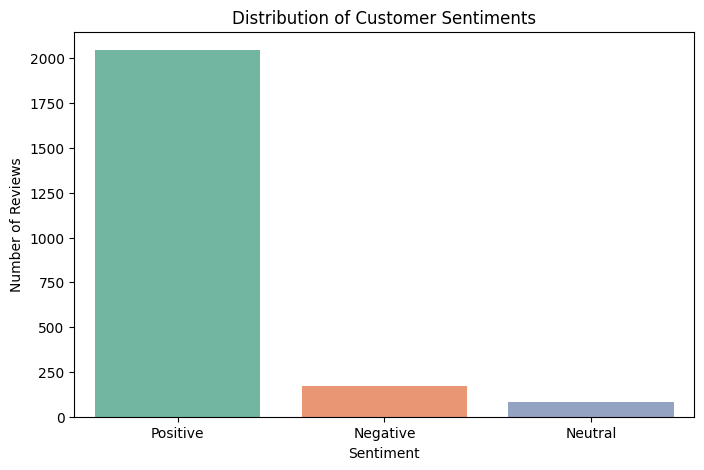

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    x='Sentiment',
    data=df,
    palette='Set2'
)

plt.title("Distribution of Customer Sentiments")

plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

SENTIMENT PERCENTAGE

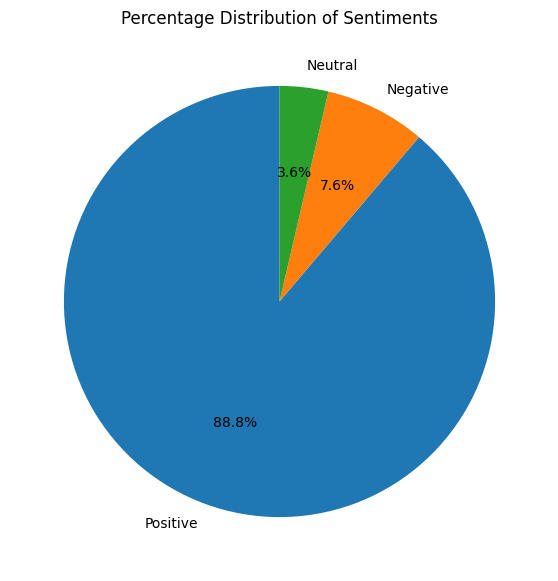

In [ ]:
sentiment_counts = df['Sentiment'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Percentage Distribution of Sentiments")

plt.show()

RATING VS SENTIMENT

This visualization compares customer ratings with the sentiment extracted from review text.

It helps determine whether textual sentiment aligns with the ratings given by customers.

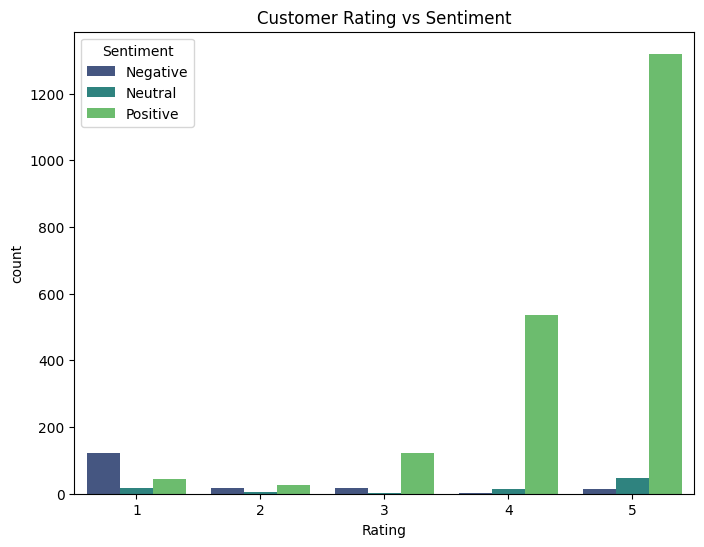

In [ ]:
plt.figure(figsize=(8,6))

sns.countplot(
    x='Rating',
    hue='Sentiment',
    data=df,
    palette='viridis'
)

plt.title("Customer Rating vs Sentiment")

plt.show()

CROSSTAB

In [ ]:
pd.crosstab(df['Rating'], df['Sentiment'])

Sentiment,Negative,Neutral,Positive
Rating,,,
1,122,18,44
2,17,4,25
3,18,1,121
4,2,14,536
5,15,47,1320


HEATMAP

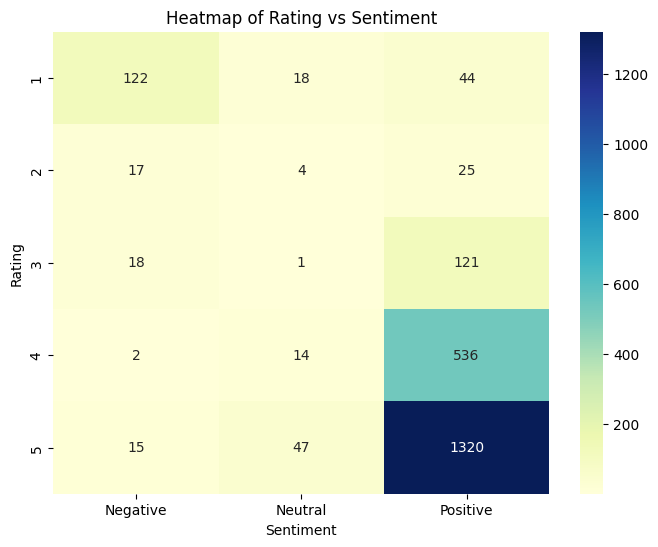

In [ ]:
plt.figure(figsize=(8,6))

sns.heatmap(
    pd.crosstab(df['Rating'], df['Sentiment']),
    annot=True,
    cmap='YlGnBu',
    fmt='d'
)

plt.title("Heatmap of Rating vs Sentiment")

plt.show()

POSITIVE WORD CLOUD

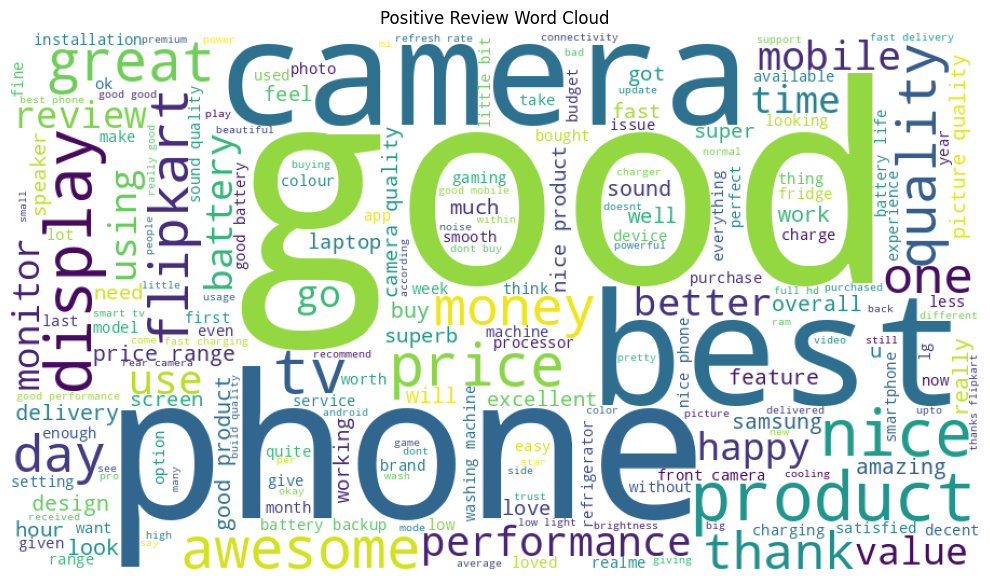

In [ ]:
positive_reviews = " ".join(
    df[df['Sentiment']=="Positive"]['Clean_Review']
)

wordcloud = WordCloud(
    width=900,
    height=500,
    background_color='white'
).generate(positive_reviews)

plt.figure(figsize=(15,7))

plt.imshow(wordcloud)

plt.axis("off")

plt.title("Positive Review Word Cloud")

plt.show()

NEGATIVE WORD CLOUD

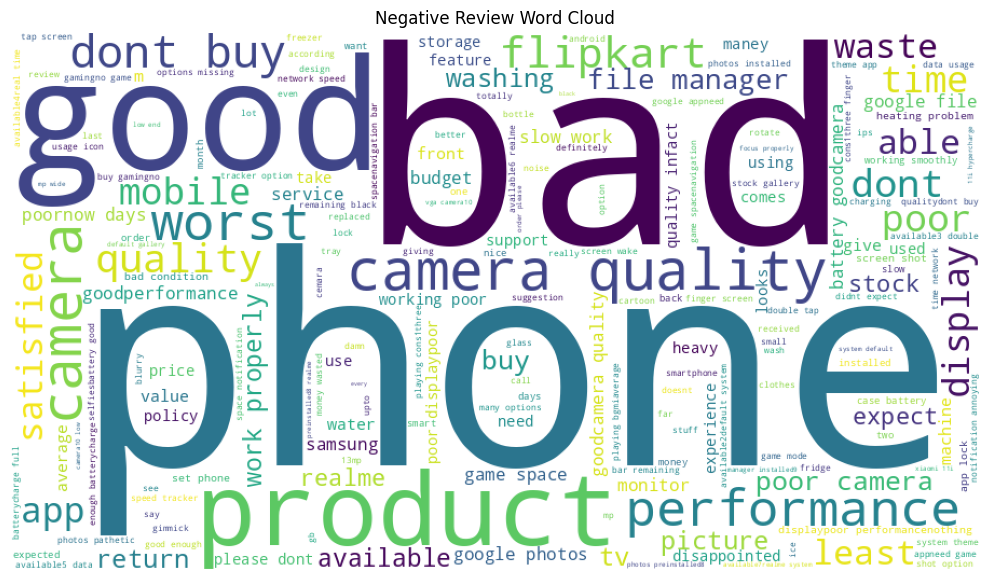

In [ ]:
negative_reviews = " ".join(
    df[df['Sentiment']=="Negative"]['Clean_Review']
)

wordcloud = WordCloud(
    width=900,
    height=500,
    background_color='white'
).generate(negative_reviews)

plt.figure(figsize=(15,7))

plt.imshow(wordcloud)

plt.axis("off")

plt.title("Negative Review Word Cloud")

plt.show()

TOP 20 MOST FREQUENT WORDS

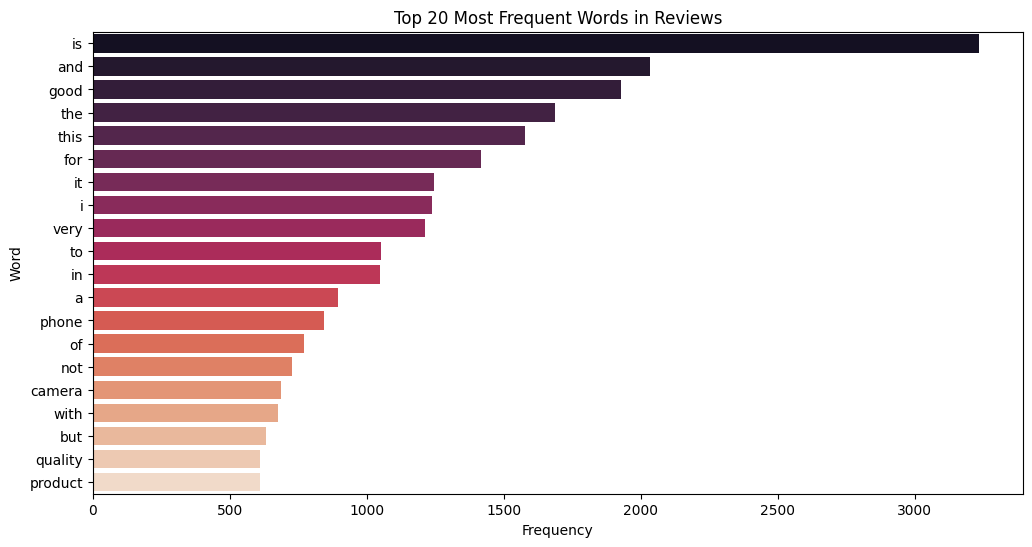

In [ ]:
from collections import Counter

all_words = " ".join(df['Clean_Review']).split()

word_freq = Counter(all_words)

common_words = pd.DataFrame(
    word_freq.most_common(20),
    columns=['Word','Frequency']
)

plt.figure(figsize=(12,6))

sns.barplot(
    x='Frequency',
    y='Word',
    data=common_words,
    palette='rocket'
)

plt.title("Top 20 Most Frequent Words in Reviews")

plt.show()